# 4.3 Simply supported beam with compression reinforcement

A stand-alone rectangular beam whose depth is restricted, so K exceeds K′.

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `L` | Effective span | m | > 0 |
| `bw`, `h` | Width, overall depth | mm | > 0 |
| `gk`, `qk` | Permanent (with self-weight) and variable load, characteristic | kN/m | ≥ 0 |
| `fck`, `fyk` | Concrete and steel strength | N/mm² | 12 to 50; 400 to 600 |
| `dg` | Largest aggregate | mm | > 0 |
| `psi2` | Quasi-permanent factor |  | 0.3 for homes and offices |
| `exposure` | Exposure class |  | `"X0"`, `"XC1"` to `"XC4"`, `"XD1"` to `"XD3"`, `"XS1"` to `"XS3"` |
| `R` | Fire rating | minutes | 30, 60, 90, 120 |
| `link`, `phi`, `phi2` | Link, bottom bar, top bar | mm | 8, 10, 12, 16, 20, 25, 32 |
| `t` | Width of each support | mm | > 0 |
| `nb`, `n_top` | Bottom bars in two layers; top bars |  | nb 3 or more |
| `legs`, `s_link`, `leg` | Link legs, link spacing, bend leg | mm |  |

In [2]:
# INPUTS: edit only this cell, then run the cells below it
L, bw, h, gk, qk = 6.0, 300, 500, 30.0, 20.0        # m, mm, mm, kN/m (incl. self-weight), kN/m
fck, fyk, dg, psi2 = 30, 500, 20, 0.3               # N/mm², N/mm², aggregate mm, -
exposure, R, link, phi, t = "XC1", 60, 10, 25, 300  # t = width of each support (mm)
nb, phi2 = 5, 20                                       # bottom bars (two layers), top bar size (mm)
n_top, legs, s_link, leg = 3, 2, 200, 250           # top bars, link legs, link spacing (mm), bend leg (mm)

## Doubly reinforced beam

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* 300 × 500, 6.0 m span

### Materials

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 3.1 | Concrete cylinder strength (project input): $f_{ck}$ | $f_{ck} = 30$ N/mm²<br><small>(= 30 MPa)</small> |
| EC2 3.2.2(3) | Steel yield strength (project input): $f_{yk}$ | $f_{yk} = 500$ N/mm²<br><small>(= 500 MPa)</small> |
| EC2 2.4.2.4, Table 2.1N | Partial factor, concrete: $\gamma_{c}$ | $\gamma_{c} = 1.5$  |
| EC2 2.4.2.4, Table 2.1N | Partial factor, reinforcement: $\gamma_{s}$ | $\gamma_{s} = 1.15$  |
| EC2 3.1.6(1), NA | Flexure and axial load (UK National Annex): $\alpha_{cc}$ | $\alpha_{cc} = 0.85$  |
| EC2 Exp. (3.15) | $f_{cd} = \dfrac{\alpha_{cc}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{0.85\times 30}{1.5}$ | $\mathbf{f_{cd} = 17}$ N/mm²<br><small>(= 17 MPa)</small> |
| EC2 3.2.7, Fig. 3.8 | $f_{yd} = \dfrac{f_{yk}}{\gamma_{s}}$<br>$\quad = \dfrac{500}{1.15}$ | $\mathbf{f_{yd} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Table 3.1 | $f_{ctm} = 0.3\,f_{ck}^{2/3}$<br>$\quad = 0.3\times 30^{2/3}$ | $\mathbf{f_{ctm} = 2.896}$ N/mm²<br><small>(= 2.896 MPa)</small> |
| EC2 3.2.7(4) | Steel modulus: $E_{s}$ | $E_{s} = 200000$ N/mm²<br><small>(= 200000 MPa)</small> |


### Actions and analysis

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $h$ | $h = 500$ mm |
|  | Effective span: $L$ | $L = 6$ m |
|  | $g_{k}$ | $g_{k} = 30$ kN/m |
|  | $q_{k}$ | $q_{k} = 20$ kN/m |
| EN 1990 Exp. (6.10) | $w_{Ed} = 1.35\,g_{k} + 1.5\,q_{k}$<br>$\quad = 1.35\times 30 + 1.5\times 20$ | $\mathbf{w_{Ed} = 70.5}$ kN/m |
|  | $M_{max} = \dfrac{w_{Ed}\,L^{2}}{8}$<br>$\quad = \dfrac{70.5\times 6^{2}}{8}$ | $\mathbf{M_{max} = 317.2}$ kN·m |
|  | $V_{max} = \dfrac{w_{Ed}\,L}{2}$<br>$\quad = \dfrac{70.5\times 6}{2}$ | $\mathbf{V_{max} = 211.5}$ kN |


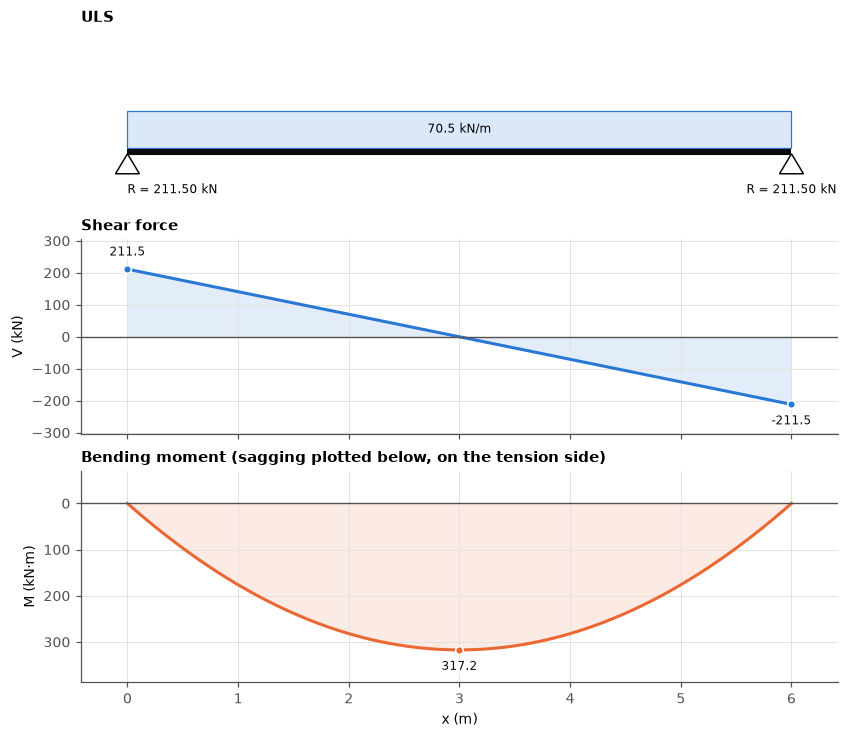

### Durability – nominal cover

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Main bar diameter: $\phi$ | $\phi = 25$ mm |
| EC2 Table 4.1, 4.4N | Exposure XC1, class S4: $c_{min,dur}$ | $c_{min,dur} = 15$ mm |
| EC2 4.4.1.3(1) | Allowance for deviation: $\Delta c_{dev}$ | $\Delta c_{dev} = 10$ mm |
|  | Link diameter: $\phi_{link}$ | $\phi_{link} = 10$ mm |
| EC2 Exp. (4.1), (4.2) | To the link<br>$c_{nom,link} = \max\left\{\phi_{link};\; c_{min,dur};\; 10\right\} + \Delta c_{dev}$<br>$\quad = \max\left\{10;\; 15;\; 10\right\} + 10$ | $\mathbf{c_{nom,link} = 25}$ mm |
| EC2 Exp. (4.1), (4.2) | To the link, so that the main bar complies<br>$c_{nom,bar} = \max\left\{\phi;\; c_{min,dur};\; 10\right\} + \Delta c_{dev} - \phi_{link}$<br>$\quad = \max\left\{25;\; 15;\; 10\right\} + 10 - 10$ | $\mathbf{c_{nom,bar} = 25}$ mm |
|  | $c_{req} = \max\left\{c_{nom,link};\; c_{nom,bar}\right\}$<br>$\quad = \max\left\{25;\; 25\right\}$ | $\mathbf{c_{req} = 25}$ mm |
|  | Cover adopted: $c_{nom}$ | $c_{nom} = 25$ mm |
| EC2 4.4.1 | **Check:** nominal cover<br>$c_{nom} = 25 \ge c_{req} = 25$ mm | ✅ **PASS**<br>ratio 1.00 |
| NA to EC2, 4.4.1.2(5) | UK projects: confirm concrete quality and cover against BS 8500-1 Tables A.4/A.5 as the UK NA requires. |  |


### Effective depths

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 8.2(2) | Centroid of 5 bars: 3 in the first layer, 2 in the second<br>$y_{bar} = c_{nom} + \phi_{link} + \dfrac{\phi}{2} + \dfrac{2}{5}\,\left(\phi + \max\left\{\phi;\; 25\right\}\right)$<br>$\quad = 25 + 10 + \dfrac{25}{2} + \dfrac{2}{5}\times \left(25 + \max\left\{25;\; 25\right\}\right)$ | $\mathbf{y_{bar} = 67.5}$ mm |
|  | $d = h - y_{bar}$<br>$\quad = 500 - 67.5$ | $\mathbf{d = 432.5}$ mm |
|  | $\phi_{2}$ | $\phi_{2} = 20$ mm |
|  | $d_{2} = c_{nom} + \phi_{link} + \dfrac{\phi_{2}}{2}$<br>$\quad = 25 + 10 + \dfrac{20}{2}$ | $\mathbf{d_{2} = 45}$ mm |


### Fire resistance

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Axis distance, soffit: $a_{prov}$ | $a_{prov} = 47.5$ mm |
|  | Axis distance, side: $a_{sd,prov}$ | $a_{sd,prov} = 47.5$ mm |
| EN 1992-1-2 Table 5.5 | R 60, tabulated width 300 mm: $a_{req}$ | $a_{req} = 25$ mm |
| EN 1992-1-2 Table 5.5 | Corner bars (no increase; width limit 200 mm): $a_{sd,req}$ | $a_{sd,req} = 25$ mm |
| EN 1992-1-2 Table 5.5 | **Check:** fire – axis distance<br>$a_{prov} = 47.5 \ge a_{req} = 25$ mm | ✅ **PASS**<br>ratio 0.53 |
| EN 1992-1-2 Table 5.5 | **Check:** fire – side axis distance<br>$a_{sd,prov} = 47.5 \ge a_{sd,req} = 25$ mm | ✅ **PASS**<br>ratio 0.53 |


In [3]:
s = Sheet("Doubly reinforced beam", element=f"{bw} × {h}, {L} m span")
n1 = math.ceil(nb / 2)      # bars in the first bottom layer
D.materials(s, fck, fyk, BRIEF["ndp"]); s.let("h", h, "mm")
s.let("L", L, "m", "Effective span"); s.let("g_k", gk, "kN/m"); s.let("q_k", qk, "kN/m")
s.calc("w_Ed", "1.35*g_k + 1.5*q_k", "kN/m", "EN 1990 Exp. (6.10)"); s.calc("M_max", "w_Ed*L**2/8", "kN·m"); s.calc("V_max", "w_Ed*L/2", "kN"); s.show("Actions and analysis")
P.determinate(DeterminateBeam(L, [UDL(s["w_Ed"])], supports=(0, L)), "ULS")
c = D.cover(s, exposure, phi, link)
s.calc("y_bar", f"c_nom + phi_link + phi/2 + ({nb - n1}/{nb})*(phi + max(phi, 25))", "mm", "EC2 8.2(2)", f"Centroid of {nb} bars: {n1} in the first layer, {nb - n1} in the second"); s.calc("d", "h - y_bar", "mm"); s.let("phi_2", phi2, "mm"); s.calc("d_2", "c_nom + phi_link + phi_2/2", "mm"); s.show("Effective depths")
d = s["d"]; D.fire_beam(s, R, bw, c + link + phi / 2, c + link + phi / 2, False)

## Bending

In [4]:
As, A2 = D.flexure(s, s["M_max"], bw, d, d2=s["d_2"]); s.show("Bending")
Ap = D.beam_bars(s, nb, phi, bw, c, link, dg, "bottom, two layers", layers=2); s.let("A_2", D.area(phi2, n_top), "mm²", f"{n_top}H{phi2} compression"); s.check("A_2", ">=", "A_s2_req", "compression steel", "EC2 6.1"); s.provide(f"{n_top}H{phi2} top"); s.show("Bars")

### Bending

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.5(4) | Redistributed / elastic moment: $\delta$ | $\delta = 1$  |
| EC2 5.5(4), NA | UK National Annex: $k_{1}$ | $k_{1} = 0.4$  |
| EC2 5.5(4), NA | UK National Annex: $k_{2}$ | $k_{2} = 1$  |
| EC2 Exp. (3.19) | Stress-block depth factor, fck ≤ 50: $\lambda$ | $\lambda = 0.8$  |
| EC2 Exp. (3.21) | Stress-block strength factor, fck ≤ 50: $\eta$ | $\eta = 1$  |
| EC2 5.5(4), 5.6.3(2) | x/d limit. The 0.45 ceiling is the EC2 5.6.3(2) ductility value, kept for every section<br>$\xi_{lim} = \min\left\{\dfrac{\delta - k_{1}}{k_{2}};\; 0.45\right\}$<br>$\quad = \min\left\{\dfrac{1 - 0.4}{1};\; 0.45\right\}$ | $\mathbf{\xi_{lim} = 0.45}$ |
| EC2 3.1.7(3) (Notebook 2.2) | $K' = \dfrac{\eta\,f_{cd}}{f_{ck}}\,\lambda\,\xi_{lim}\,\left(1 - \dfrac{\lambda\,\xi_{lim}}{2}\right)$<br>$\quad = \dfrac{1\times 17}{30}\times 0.8\times 0.45\times \left(1 - \dfrac{0.8\times 0.45}{2}\right)$ | $\mathbf{K' = 0.167}$ |
|  | Design moment: $M_{Ed}$ | $M_{Ed} = 317.2$ kN·m |
|  | $b$ | $b = 300$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{317.2\times 10^{6}}{300\times 432.5^{2}\times 30}$ | $\mathbf{K = 0.188}$ |
| EC2 6.1 | K > K′ so compression reinforcement is required. |  |
|  | $x = \xi_{lim}\,d$<br>$\quad = 0.45\times 432.5$ | $\mathbf{x = 194.6}$ mm |
|  | $z = d - \dfrac{\lambda\,x}{2}$<br>$\quad = 432.5 - \dfrac{0.8\times 194.6}{2}$ | $\mathbf{z = 354.6}$ mm |
| EC2 6.1(2)P, Table 3.1 | Compression steel strain<br>$\varepsilon_{s2} = \dfrac{0.0035\,\left(x - d_{2}\right)}{x}$<br>$\quad = \dfrac{0.0035\times \left(194.6 - 45\right)}{194.6}$ | $\mathbf{\varepsilon_{s2} = 0.00269}$ |
| EC2 Fig. 3.8 | $f_{s2} = \min\left\{E_{s}\,\varepsilon_{s2};\; f_{yd}\right\}$<br>$\quad = \min\left\{200000\times 0.00269;\; 434.8\right\}$ | $\mathbf{f_{s2} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 6.1 (Notebook 2.2) | $A_{s2,req} = \dfrac{\left(K - K'\right)\,f_{ck}\,b\,d^{2}}{f_{s2}\,\left(d - d_{2}\right)}$<br>$\quad = \dfrac{\left(0.188 - 0.167\right)\times 30\times 300\times 432.5^{2}}{434.8\times \left(432.5 - 45\right)}$ | $\mathbf{A_{s2,req} = 211.5}$ mm² |
| EC2 6.1 (Notebook 2.2) | $A_{s,req} = \dfrac{K'\,f_{ck}\,b\,d^{2}}{f_{yd}\,z} + \dfrac{A_{s2,req}\,f_{s2}}{f_{yd}}$<br>$\quad = \dfrac{0.167\times 30\times 300\times 432.5^{2}}{434.8\times 354.6} + \dfrac{211.5\times 434.8}{434.8}$ | $\mathbf{A_{s,req} = 2037.9}$ mm² |
|  | Mean width of the tension zone: $b_{t}$ | $b_{t} = 300$ mm |
| EC2 Exp. (9.1N) | $A_{s,min} = \max\left\{\dfrac{0.26\,f_{ctm}}{f_{yk}}\,b_{t}\,d;\; 0.0013\,b_{t}\,d\right\}$<br>$\quad = \max\left\{\dfrac{0.26\times 2.896}{500}\times 300\times 432.5;\; 0.0013\times 300\times 432.5\right\}$ | $\mathbf{A_{s,min} = 195.4}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{2037.9;\; 195.4\right\}$ | $\mathbf{A_{s,req} = 2037.9}$ mm² |


### Bars

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Number of bars: $n_{bars}$ | $n_{bars} = 5$  |
|  | $A_{s,prov} = \dfrac{n_{bars}\,\pi\,\phi^{2}}{4}$<br>$\quad = \dfrac{5\times \pi\times 25^{2}}{4}$ | $\mathbf{A_{s,prov} = 2454.4}$ mm² |
| EC2 6.1, 9.2.1.1 | **Check:** area provided bottom, two layers<br>$A_{s,prov} = 2454.4 \ge A_{s,req} = 2037.9$ mm² | ✅ **PASS**<br>ratio 0.83 |
|  | $b_{w}$ | $b_{w} = 300$ mm |
|  | Maximum aggregate size (project input): $d_{g}$ | $d_{g} = 20$ mm |
|  | Bars in one layer: $n_{layer}$ | $n_{layer} = 3$  |
|  | $s_{clear} = \dfrac{b_{w} - 2\,c_{nom} - 2\,\phi_{link} - n_{layer}\,\phi}{n_{layer} - 1}$<br>$\quad = \dfrac{300 - 2\times 25 - 2\times 10 - 3\times 25}{3 - 1}$ | $\mathbf{s_{clear} = 77.5}$ mm |
| EC2 8.2(2), k₁ = 1, k₂ = 5 mm | $s_{min} = \max\left\{\phi;\; d_{g} + 5;\; 20\right\}$<br>$\quad = \max\left\{25;\; 20 + 5;\; 20\right\}$ | $\mathbf{s_{min} = 25}$ mm |
| EC2 8.2(2) | **Check:** clear bar spacing bottom, two layers<br>$s_{clear} = 77.5 \ge s_{min} = 25$ mm | ✅ **PASS**<br>ratio 0.32 |
| EC2 9.2.1.1(3) | $A_{s,max} = 0.04\,b_{w}\,h$<br>$\quad = 0.04\times 300\times 500$ | $\mathbf{A_{s,max} = 6000}$ mm² |
| EC2 9.2.1.1(3) | **Check:** maximum steel bottom, two layers<br>$A_{s,prov} = 2454.4 \le A_{s,max} = 6000$ mm² | ✅ **PASS**<br>ratio 0.41 |
|  | **PROVIDE: 5H25 bottom, two layers (2454 mm²)** | 🟦 **5H25 bottom, two layers (2454 mm²)** |
|  | 3H20 compression: $A_{2}$ | $A_{2} = 942.5$ mm² |
| EC2 6.1 | **Check:** compression steel<br>$A_{2} = 942.5 \ge A_{s2,req} = 211.5$ mm² | ✅ **PASS**<br>ratio 0.22 |
|  | **PROVIDE: 3H20 top** | 🟦 **3H20 top** |


## Shear, deflection, cracking, anchorage

### Shear

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Shear at face of support: $V_{Ed,face}$ | $V_{Ed,face} = 200.9$ kN |
| EC2 6.2.1(8) | Shear at d from face: $V_{Ed,d}$ | $V_{Ed,d} = 170.4$ kN |
| EC2 Fig. 6.3 | Anchored tension steel: $A_{sl}$ | $A_{sl} = 1472.6$ mm² |
| EC2 6.2.2(1), NA | $C_{Rd,c} = \dfrac{0.18}{\gamma_{c}}$<br>$\quad = \dfrac{0.18}{1.5}$ | $\mathbf{C_{Rd,c} = 0.12}$ |
| EC2 6.2.2(1) | $k = \min\left\{1 + \sqrt{\dfrac{200}{d}};\; 2\right\}$<br>$\quad = \min\left\{1 + \sqrt{\dfrac{200}{432.5}};\; 2\right\}$ | $\mathbf{k = 1.68}$ |
| EC2 6.2.2(1) | $\rho_{l} = \min\left\{\dfrac{A_{sl}}{b_{w}\,d};\; 0.02\right\}$<br>$\quad = \min\left\{\dfrac{1472.6}{300\times 432.5};\; 0.02\right\}$ | $\mathbf{\rho_{l} = 0.01135}$ |
| EC2 Exp. (6.3N) | $v_{min} = 0.035\,k^{1.5}\,\sqrt{f_{ck}}$<br>$\quad = 0.035\times 1.68^{1.5}\times \sqrt{30}$ | $\mathbf{v_{min} = 0.417}$ N/mm²<br><small>(= 0.417 MPa)</small> |
| EC2 Exp. (6.2a), (6.2b) | $V_{Rd,c} = \dfrac{\max\left\{C_{Rd,c}\,k\,\left(100\,\rho_{l}\,f_{ck}\right)^{1/3};\; v_{min}\right\}\,b_{w}\,d}{1000}$<br>$\quad = \dfrac{\max\left\{0.12\times 1.68\times \left(100\times 0.01135\times 30\right)^{1/3};\; 0.417\right\}\times 300\times 432.5}{1000}$ | $\mathbf{V_{Rd,c} = 84.78}$ kN |
| EC2 6.2.1(3)–(5) | V<sub>Ed</sub> > V<sub>Rd,c</sub>: design shear links. |  |
| EC2 6.2.3(3) Note 3 | Non-prestressed: $\alpha_{cw}$ | $\alpha_{cw} = 1$  |
| EC2 Exp. (6.6N); NA 6.2.3(3) | $\nu_{1} = 0.6\,\left(1 - \dfrac{f_{ck}}{250}\right)$<br>$\quad = 0.6\times \left(1 - \dfrac{30}{250}\right)$ | $\mathbf{\nu_{1} = 0.528}$ |
| NA 3.1.6(1) | α_cc for shear: $\alpha_{cc,v}$ | $\alpha_{cc,v} = 1$  |
| EC2 Exp. (3.15) | $f_{cd,v} = \dfrac{\alpha_{cc,v}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{1\times 30}{1.5}$ | $\mathbf{f_{cd,v} = 20}$ N/mm²<br><small>(= 20 MPa)</small> |
| EC2 6.2.3(1) | $z_{v} = 0.9\,d$<br>$\quad = 0.9\times 432.5$ | $\mathbf{z_{v} = 389.2}$ mm |
| EC2 Exp. (6.9), cot θ = 1 | $V_{Rd,max,45} = \dfrac{\dfrac{\alpha_{cw}\,b_{w}\,z_{v}\,\nu_{1}\,f_{cd,v}}{1 + 1}}{1000}$<br>$\quad = \dfrac{\dfrac{1\times 300\times 389.2\times 0.528\times 20}{1 + 1}}{1000}$ | $\mathbf{V_{Rd,max,45} = 616.6}$ kN |
| EC2 6.2.1(8), 6.2.3(3) | **Check:** strut crushing at face<br>$V_{Ed,face} = 200.9 \le V_{Rd,max,45} = 616.6$ kN | ✅ **PASS**<br>ratio 0.33 |
| EC2 Exp. (6.9) rearranged (Notebook 2.3) | Strut angle that just satisfies V_Rd,max<br>$\theta_{min} = \dfrac{0.5\,\sin^{-1}\!\left(\min\left\{\dfrac{V_{Ed,face}}{V_{Rd,max,45}};\; 1\right\}\right)\times 180}{\pi}$<br>$\quad = \dfrac{0.5\times \sin^{-1}\!\left(\min\left\{\dfrac{200.9}{616.6};\; 1\right\}\right)\times 180}{\pi}$ | $\mathbf{\theta_{min} = 9.509}$ ° |
| EC2 Exp. (6.7N), NA | Limited to 1 ≤ cot θ ≤ 2.5: $\cot\theta$ | $\cot\theta = 2.5$  |
| EC2 Exp. (6.8) | $A_{sw,s,req} = \dfrac{V_{Ed,d}\times 1000}{z_{v}\,f_{yd}\,\cot\theta}$<br>$\quad = \dfrac{170.4\times 1000}{389.2\times 434.8\times 2.5}$ | $\mathbf{A_{sw,s,req} = 0.403}$ mm²/mm |
| EC2 Exp. (9.4), (9.5N) | $A_{sw,s,min} = \dfrac{0.08\,\sqrt{f_{ck}}}{f_{yk}}\,b_{w}$<br>$\quad = \dfrac{0.08\times \sqrt{30}}{500}\times 300$ | $\mathbf{A_{sw,s,min} = 0.263}$ mm²/mm |
|  | Number of legs: $n_{legs}$ | $n_{legs} = 2$  |
|  | Link spacing: $s_{link}$ | $s_{link} = 200$ mm |
|  | $A_{sw,s} = \dfrac{\dfrac{n_{legs}\,\pi\,\phi_{link}^{2}}{4}}{s_{link}}$<br>$\quad = \dfrac{\dfrac{2\times \pi\times 10^{2}}{4}}{200}$ | $\mathbf{A_{sw,s} = 0.785}$ mm²/mm |
| EC2 9.2.2(5) | **Check:** minimum links<br>$A_{sw,s} = 0.785 \ge A_{sw,s,min} = 0.263$ mm²/mm | ✅ **PASS**<br>ratio 0.33 |
| EC2 6.2.3(3) | **Check:** design links<br>$A_{sw,s} = 0.785 \ge A_{sw,s,req} = 0.403$ mm²/mm | ✅ **PASS**<br>ratio 0.51 |
| EC2 Exp. (9.6N) | $s_{l,max} = 0.75\,d$<br>$\quad = 0.75\times 432.5$ | $\mathbf{s_{l,max} = 324.4}$ mm |
| EC2 9.2.2(6) | **Check:** longitudinal link spacing<br>$s_{link} = 200 \le s_{l,max} = 324.4$ mm | ✅ **PASS**<br>ratio 0.62 |
| EC2 Exp. (9.8N) | Maximum transverse leg spacing: $s_{t,max}$ | $s_{t,max} = 324.4$ mm |
| EC2 Exp. (6.8) | Resistance of the links provided<br>$V_{Rd,s} = \dfrac{A_{sw,s}\,z_{v}\,f_{yd}\,\cot\theta}{1000}$<br>$\quad = \dfrac{0.785\times 389.2\times 434.8\times 2.5}{1000}$ | $\mathbf{V_{Rd,s} = 332.3}$ kN |
|  | **PROVIDE: H10 – 2 legs @ 200 mm ** | 🟦 **H10 – 2 legs @ 200 mm ** |


### Links to compression bars

| Reference | Calculation | Output |
|:--|:--|:--|
|  | 15 φ of the compression bars: $s_{comp}$ | $s_{comp} = 300$ mm |
| EC2 9.2.1.2(3) | **Check:** links hold the compression bars<br>$s_{link} = 200 \le s_{comp} = 300$ mm | ✅ **PASS**<br>ratio 0.67 |


### Deflection

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 7.4N / NA.5 | Structural system: simply supported: $K_{sys}$ | $K_{sys} = 1$  |
|  | Effective span: $l_{eff}$ | $l_{eff} = 6000$ mm |
| EC2 7.4.2(2) | 10⁻³ √fck: $\rho_{0}$ | $\rho_{0} = 0.00548$  |
|  | Steel required for ULS at mid-span: $A_{s,ult}$ | $A_{s,ult} = 2037.9$ mm² |
| EC2 7.4.2(2) | $\rho = \dfrac{A_{s,ult}}{b\,d}$<br>$\quad = \dfrac{2037.9}{300\times 432.5}$ | $\mathbf{\rho = 0.01571}$ |
| EC2 7.4.2(2) | Compression steel ratio: $\rho'$ | $\rho' = 0.00163$  |
| EC2 Exp. (7.16b) | Basic l/d<br>$N_{basic} = K_{sys}\,\left(11 + \dfrac{1.5\,\sqrt{f_{ck}}\,\rho_{0}}{\rho - \rho'} + \dfrac{\sqrt{f_{ck}}}{12}\,\sqrt{\dfrac{\rho'}{\rho_{0}}}\right)$<br>$\quad = 1\times \left(11 + \dfrac{1.5\times \sqrt{30}\times 0.00548}{0.01571 - 0.00163} + \dfrac{\sqrt{30}}{12}\times \sqrt{\dfrac{0.00163}{0.00548}}\right)$ | $\mathbf{N_{basic} = 14.45}$ |
| EC2 7.4.2(2) | Flanged section, b_f/b_w = 1.00: $F_{1}$ | $F_{1} = 1$  |
| EC2 7.4.2(2) | Span > 7 m with brittle partitions: $F_{2}$ | $F_{2} = 1$  |
| NA Table NA.5 Note 5 | Cap on the steel-stress factor: $F_{cap}$ | $F_{cap} = 1.5$  |
| EC2 Exp. (7.17), NA Note 5 | $F_{3} = \min\left\{\dfrac{500}{\dfrac{f_{yk}\,A_{s,ult}}{A_{s,prov}}};\; F_{cap}\right\}$<br>$\quad = \min\left\{\dfrac{500}{\dfrac{500\times 2037.9}{2454.4}};\; 1.5\right\}$ | $\mathbf{F_{3} = 1.204}$ |
| NA Table NA.5 Note 6 | Absolute limit 40K: $N_{abs}$ | $N_{abs} = 40$  |
| EC2 7.4.2(2), NA | $N_{allow} = \min\left\{N_{basic}\,F_{1}\,F_{2}\,F_{3};\; N_{abs}\,K_{sys}\right\}$<br>$\quad = \min\left\{14.45\times 1\times 1\times 1.204;\; 40\times 1\right\}$ | $\mathbf{N_{allow} = 17.4}$ |
|  | $N_{actual} = \dfrac{l_{eff}}{d}$<br>$\quad = \dfrac{6000}{432.5}$ | $\mathbf{N_{actual} = 13.87}$ |
| EC2 7.4.2 | **Check:** deflection (span/depth)<br>$N_{actual} = 13.87 \le N_{allow} = 17.4$  | ✅ **PASS**<br>ratio 0.80 |


### Cracking

| Reference | Calculation | Output |
|:--|:--|:--|
| EN 1990 Table A1.1 | Quasi-permanent factor: $\psi_{2}$ | $\psi_{2} = 0.3$  |
|  | Permanent load on the member: $G_{k}$ | $G_{k} = 30$  |
|  | Variable load on the member: $Q_{k}$ | $Q_{k} = 20$  |
| EN 1990 (6.16b); method as JRC EUR 26566 (2014) 3.3.1.3 | Steel stress, quasi-permanent load<br>$\sigma_{s} = \dfrac{\dfrac{\dfrac{f_{yd}\,\left(G_{k} + \psi_{2}\,Q_{k}\right)}{1.35\,G_{k} + 1.5\,Q_{k}}\,A_{s,ult}}{A_{s,prov}}}{\delta}$<br>$\quad = \dfrac{\dfrac{\dfrac{434.8\times \left(30 + 0.3\times 20\right)}{1.35\times 30 + 1.5\times 20}\times 2037.9}{2454.4}}{1}$ | $\mathbf{\sigma_{s} = 184.3}$ N/mm²<br><small>(= 184.3 MPa)</small> |
| EC2 Table 7.3N, NA.4 | Maximum bar spacing, w_k = 0.3 mm (next higher tabulated stress, no interpolation): $s_{crack}$ | $s_{crack} = 250$ mm |
|  | Bar spacing provided (centres): $s_{bars}$ | $s_{bars} = 102.5$ mm |
| EC2 7.3.3(2) | **Check:** crack control<br>$s_{bars} = 102.5 \le s_{crack} = 250$ mm | ✅ **PASS**<br>ratio 0.41 |
| EC2 Exp. (7.2) | Bending, σ_c = 0: $k_{c}$ | $k_{c} = 0.4$  |
| EC2 7.3.2(2) | Coefficient k, interpolated on depth: $k_{h}$ | $k_{h} = 0.86$  |
| EC2 7.3.2(2) | Tension zone before cracking<br>$A_{ct} = \dfrac{b\,h}{2}$<br>$\quad = \dfrac{300\times 500}{2}$ | $\mathbf{A_{ct} = 75000}$ mm² |
| EC2 Exp. (7.1), σ_s = f_yk | $A_{s,crack} = \dfrac{k_{c}\,k_{h}\,f_{ctm}\,A_{ct}}{f_{yk}}$<br>$\quad = \dfrac{0.4\times 0.86\times 2.896\times 75000}{500}$ | $\mathbf{A_{s,crack} = 149.5}$ mm² |
| EC2 7.3.2 | **Check:** minimum steel for cracking<br>$A_{s,prov} = 2454.4 \ge A_{s,crack} = 149.5$ mm² | ✅ **PASS**<br>ratio 0.06 |


### Anchorage

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $V_{Ed}$ | $V_{Ed} = 200.9$ kN |
| EC2 Exp. (9.2) | $a_{l} = \dfrac{z_{v}\,\cot\theta}{2}$<br>$\quad = \dfrac{389.2\times 2.5}{2}$ | $\mathbf{a_{l} = 486.6}$ mm |
| EC2 Exp. (9.3) | $F_{E} = \dfrac{V_{Ed}\,a_{l}}{z_{v}}$<br>$\quad = \dfrac{200.9\times 486.6}{389.2}$ | $\mathbf{F_{E} = 251.2}$ kN |
|  | 3H25 carried to the support: $A_{s,prov}$ | $A_{s,prov} = 1472.6$ mm² |
|  | $\sigma_{E} = \dfrac{F_{E}\times 1000}{A_{s,prov}}$<br>$\quad = \dfrac{251.2\times 1000}{1472.6}$ | $\mathbf{\sigma_{E} = 170.6}$ N/mm²<br><small>(= 170.6 MPa)</small> |
| EC2 Table 3.1 | $f_{ctk,005} = 0.7\,f_{ctm}$<br>$\quad = 0.7\times 2.896$ | $\mathbf{f_{ctk,005} = 2.028}$ N/mm²<br><small>(= 2.028 MPa)</small> |
| EC2 3.1.6(2), NA | $\alpha_{ct}$ | $\alpha_{ct} = 1$  |
| EC2 Exp. (3.16) | $f_{ctd} = \dfrac{\alpha_{ct}\,f_{ctk,005}}{\gamma_{c}}$<br>$\quad = \dfrac{1\times 2.028}{1.5}$ | $\mathbf{f_{ctd} = 1.352}$ N/mm²<br><small>(= 1.352 MPa)</small> |
| EC2 8.4.2, Fig. 8.2 | Good bond: $\eta_{1}$ | $\eta_{1} = 1$  |
| EC2 8.4.2 | φ ≤ 32 mm: $\eta_{2}$ | $\eta_{2} = 1$  |
| EC2 Exp. (8.2) | $f_{bd} = 2.25\,\eta_{1}\,\eta_{2}\,f_{ctd}$<br>$\quad = 2.25\times 1\times 1\times 1.352$ | $\mathbf{f_{bd} = 3.041}$ N/mm²<br><small>(= 3.041 MPa)</small> |
| EC2 8.4.3(2) | Design bar stress: $\sigma_{sd}$ | $\sigma_{sd} = 170.6$ N/mm²<br><small>(= 170.6 MPa)</small> |
| EC2 Exp. (8.3) | $l_{b,rqd} = \dfrac{\dfrac{\phi}{4}\,\sigma_{sd}}{f_{bd}}$<br>$\quad = \dfrac{\dfrac{25}{4}\times 170.6}{3.041}$ | $\mathbf{l_{b,rqd} = 350.5}$ mm |
| EC2 Table 8.2 | Cover coefficient (others = 1.0, conservative): $\alpha_{2}$ | $\alpha_{2} = 1$  |
| EC2 Exp. (8.6)/(8.7) | Tension: $f_{lmin}$ | $f_{lmin} = 0.3$  |
| EC2 8.4.4(1) | $l_{b,min} = \max\left\{f_{lmin}\,l_{b,rqd};\; 10\,\phi;\; 100\right\}$<br>$\quad = \max\left\{0.3\times 350.5;\; 10\times 25;\; 100\right\}$ | $\mathbf{l_{b,min} = 250}$ mm |
| EC2 Exp. (8.4) | $l_{bd} = \max\left\{\alpha_{2}\,l_{b,rqd};\; l_{b,min}\right\}$<br>$\quad = \max\left\{1\times 350.5;\; 250\right\}$ | $\mathbf{l_{bd} = 350.5}$ mm |
|  | Support width: $W$ | $W = 300$ mm |
|  | Straight length available<br>$l_{straight} = W - c_{nom}$<br>$\quad = 300 - 25$ | $\mathbf{l_{straight} = 275}$ mm |
| EC2 8.4.1(2), Fig. 8.1 | A straight bar does not have enough length, so a 90° bend is provided. |  |
| NA Table NA.6a | Minimum mandrel diameter / φ: $k_{m}$ | $k_{m} = 7$  |
|  | Radius of the bar centre-line<br>$r_{c} = \dfrac{k_{m}\,\phi + \phi}{2}$<br>$\quad = \dfrac{7\times 25 + 25}{2}$ | $\mathbf{r_{c} = 100}$ mm |
|  | Vertical leg, from the centre of the horizontal bar: $l_{leg}$ | $l_{leg} = 250$ mm |
| EC2 8.4.3(3) | Length along the centre-line<br>$l_{bent} = W - c_{nom} - \dfrac{\phi}{2} + l_{leg} - \left(2 - \dfrac{\pi}{2}\right)\,r_{c}$<br>$\quad = 300 - 25 - \dfrac{25}{2} + 250 - \left(2 - \dfrac{\pi}{2}\right)\times 100$ | $\mathbf{l_{bent} = 469.6}$ mm |
| EC2 9.2.1.4(3), 8.4.3(3) | **Check:** bent-bar anchorage at the support<br>$l_{bent} = 469.6 \ge l_{bd} = 350.5$ mm | ✅ **PASS**<br>ratio 0.75 |
| EC2 8.3(3) | Length needed past the end of the bend<br>$l_{past} = \max\left\{l_{bd} - \left(W - c_{nom} - \dfrac{\phi}{2} - r_{c}\right) - \dfrac{\pi\,r_{c}}{2};\; 0\right\}$<br>$\quad = \max\left\{350.5 - \left(300 - 25 - \dfrac{25}{2} - 100\right) - \dfrac{\pi\times 100}{2};\; 0\right\}$ | $\mathbf{l_{past} = 30.91}$ mm |
| EC2 8.3(3) | $l_{5} = 5\,\phi$<br>$\quad = 5\times 25$ | $\mathbf{l_{5} = 125}$ mm |
| EC2 8.3(3) | **Check:** no mandrel check needed at the support<br>$l_{past} = 30.91 \le l_{5} = 125$ mm | ✅ **PASS**<br>ratio 0.25 |
| EC2 8.3(3) | Provide a cross bar of diameter ≥ φ inside the bend. |  |
|  | **PROVIDE: 90° bend, 250 mm leg at the support** | 🟦 **90° bend, 250 mm leg at the support** |


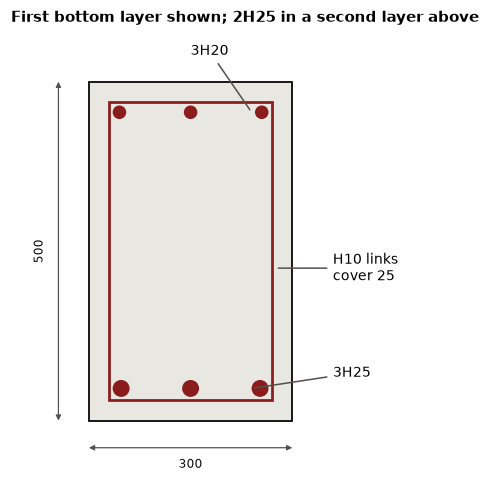

### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| nominal cover | EC2 4.4.1 | 1.00 | ✅ PASS |
| fire – axis distance | EN 1992-1-2 Table 5.5 | 0.53 | ✅ PASS |
| fire – side axis distance | EN 1992-1-2 Table 5.5 | 0.53 | ✅ PASS |
| area provided bottom, two layers | EC2 6.1, 9.2.1.1 | 0.83 | ✅ PASS |
| clear bar spacing bottom, two layers | EC2 8.2(2) | 0.32 | ✅ PASS |
| maximum steel bottom, two layers | EC2 9.2.1.1(3) | 0.41 | ✅ PASS |
| compression steel | EC2 6.1 | 0.22 | ✅ PASS |
| strut crushing at face | EC2 6.2.1(8), 6.2.3(3) | 0.33 | ✅ PASS |
| minimum links | EC2 9.2.2(5) | 0.33 | ✅ PASS |
| design links | EC2 6.2.3(3) | 0.51 | ✅ PASS |
| longitudinal link spacing | EC2 9.2.2(6) | 0.62 | ✅ PASS |
| links hold the compression bars | EC2 9.2.1.2(3) | 0.67 | ✅ PASS |
| deflection (span/depth) | EC2 7.4.2 | 0.80 | ✅ PASS |
| crack control | EC2 7.3.3(2) | 0.41 | ✅ PASS |
| minimum steel for cracking | EC2 7.3.2 | 0.06 | ✅ PASS |
| bent-bar anchorage at the support | EC2 9.2.1.4(3), 8.4.3(3) | 0.75 | ✅ PASS |
| no mandrel check needed at the support | EC2 8.3(3) | 0.25 | ✅ PASS |

**All checks pass.**

In [5]:
w = s["w_Ed"]; f = t / 2000
D.shear_beam(s, s["V_max"] - w * f, s["V_max"] - w * (f + d / 1000), bw, d, D.area(phi, n1), link, legs, s_link); s.show("Shear")
s.let("s_comp", 15 * phi2, "mm", "15 φ of the compression bars"); s.check("s_link", "<=", "s_comp", "links hold the compression bars", "EC2 9.2.1.2(3)"); s.show("Links to compression bars")
D.deflection(s, L * 1000, d, bw, As, Ap, "simply supported", As2_req=A2); s.show("Deflection")
D.crack(s, gk, qk, psi2, As, Ap, (bw - 2 * c - 2 * link - phi) / (n1 - 1), h); D.crack_min(s, bw, h, Ap); s.show("Cracking")
s.let("V_Ed", s["V_Ed_face"], "kN"); s.calc("a_l", "z_v*cot_theta/2", "mm", "EC2 Exp. (9.2)"); s.calc("F_E", "V_Ed*a_l/z_v", "kN", "EC2 Exp. (9.3)"); s.let("A_s_prov", D.area(phi, n1), "mm²", f"{n1}H{phi} carried to the support"); s.calc("sigma_E", "F_E*1000/A_s_prov", "N/mm²")
D.anchorage(s, phi, s["sigma_E"]); D.bent_anchorage(s, t, c, phi, leg, "at the support"); s.show("Anchorage")
P.beam_section(bw, h, c, link, (n_top, phi2), (n1, phi), f"First bottom layer shown; {nb - n1}H{phi} in a second layer above")
s.summary()